# 📝 Task 1: Restaurant Reviews

In [4]:
import pandas as pd
df = pd.read_csv("Dataset.csv")
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

In [12]:
import pandas as pd
import re

# Remove missing rating texts (if any)
df = df.dropna(subset=['Rating text'])

# Clean the text: keep only letters, convert to lowercase
df['Cleaned_Review'] = df['Rating text'].apply(lambda x: re.sub('[^a-zA-Z ]', '', str(x).lower()))

# Check a few cleaned reviews
df[['Rating text', 'Cleaned_Review']].head()

,Rating text,Cleaned_Review
0,Excellent,excellent
1,Excellent,excellent
2,Very Good,very good
3,Excellent,excellent
4,Excellent,excellent


In [14]:
from collections import Counter

# Combine all reviews into one text
all_words = ' '.join(df['Cleaned_Review']).split()
word_freq = Counter(all_words)

# Get most common words (positive/negative manually interpreted)
common_words = pd.DataFrame(word_freq.most_common(20), columns=['Word', 'Count'])
common_words.head(10)

,Word,Count
0,average,3737
1,good,3179
2,not,2148
3,rated,2148
4,very,1079
5,excellent,301
6,poor,186


In [16]:
df['Review_Length'] = df['Cleaned_Review'].apply(lambda x: len(x.split()))
review_corr = df[['Review_Length', 'Aggregate rating']].corr()
review_corr

,Review_Length,Aggregate rating
Review_Length,1.000000,-0.599573
Aggregate rating,-0.599573,1.000000


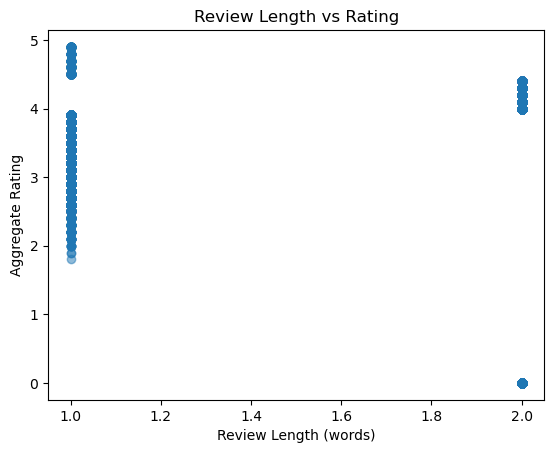

In [18]:
import matplotlib.pyplot as plt

plt.scatter(df['Review_Length'], df['Aggregate rating'], alpha=0.5)
plt.title('Review Length vs Rating')
plt.xlabel('Review Length (words)')
plt.ylabel('Aggregate Rating')
plt.show()

In [20]:
df[['Review_Length', 'Aggregate rating']].to_csv("Review_Length_Rating.csv", index=False)
common_words.to_csv("Common_Review_Words.csv", index=False)

# 📊 Task 2: Votes Analysis

In [23]:
import pandas as pd
df = pd.read_csv("Dataset.csv")
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

In [25]:
highest_votes = df.loc[df['Votes'].idxmax(), ['Restaurant Name', 'Votes', 'Aggregate rating']]
lowest_votes = df.loc[df['Votes'].idxmin(), ['Restaurant Name', 'Votes', 'Aggregate rating']]

print("Highest Votes:\n", highest_votes)
print("\nLowest Votes:\n", lowest_votes)

Highest Votes:
 Restaurant Name      Toit
Votes               10934
Aggregate rating      4.8
Name: 728, dtype: object

Lowest Votes:
 Restaurant Name     Cantinho da Gula
Votes                              0
Aggregate rating                 0.0
Name: 69, dtype: object


In [27]:
correlation = df['Votes'].corr(df['Aggregate rating'])
print("Correlation between Votes and Ratings:", correlation)

Correlation between Votes and Ratings: 0.31369058419541135


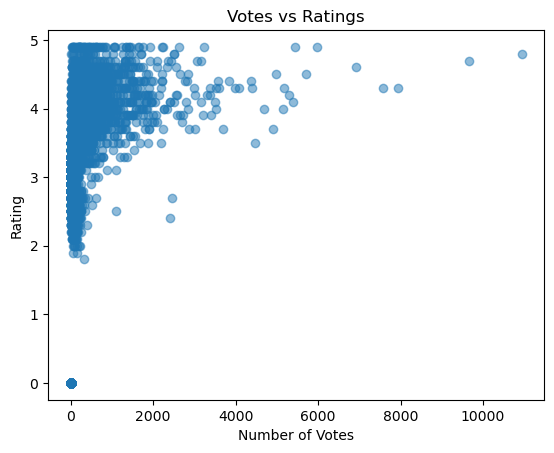

In [29]:
plt.scatter(df['Votes'], df['Aggregate rating'], alpha=0.5)
plt.title('Votes vs Ratings')
plt.xlabel('Number of Votes')
plt.ylabel('Rating')
plt.show()

In [31]:
df[['Votes', 'Aggregate rating']].to_csv("Votes_Rating.csv", index=False)

# 💰 Task 3: Price Range vs Online Delivery & Table Booking

In [34]:
import pandas as pd
df = pd.read_csv("Dataset.csv")
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

In [36]:
price_delivery = df.groupby('Price range')['Has Online delivery'].value_counts(normalize=True).unstack()
price_delivery

Has Online delivery,No,Yes
Price range,,
1,0.842259,0.157741
2,0.586894,0.413106
3,0.708097,0.291903
4,0.909556,0.090444


In [38]:
price_table = df.groupby('Price range')['Has Table booking'].value_counts(normalize=True).unstack()
price_table

Has Table booking,No,Yes
Price range,,
1,0.999775,0.000225
2,0.923225,0.076775
3,0.542614,0.457386
4,0.532423,0.467577


In [40]:
price_rating = df.groupby('Price range')['Aggregate rating'].mean()
price_rating

Price range
1    1.999887
2    2.941054
3    3.683381
4    3.817918
Name: Aggregate rating, dtype: float64

In [42]:
price_delivery.to_csv("PriceRange_Delivery.csv")
price_table.to_csv("PriceRange_TableBooking.csv")
price_rating.to_csv("PriceRange_Rating.csv")